# Praktikum Sub-CPMK-4 &mdash; Transformasi Ruang Warna untuk Analisis dan Pemrosesan Citra

**Pengolahan Citra Digital (IF2514505)** &nbsp;|&nbsp; Semester 5 &nbsp;|&nbsp; 1 SKS Praktikum &nbsp;|&nbsp; Durasi sasaran 135 menit (rentang 120&ndash;150)

**Program Studi Informatika &mdash; Institut Teknologi Kalimantan**

---

| | |
|---|---|
| **Nama** | Muhamaad Wisnu Wardhana |
| **NIM** | 11241063 |
| **Kelas / Kelompok** | A |
| **Tanggal praktikum** | 18/11/26 |

---

### Capaian yang diukur
**Sub-CPMK-4**: Mahasiswa mampu menerapkan transformasi ruang warna citra untuk keperluan analisis dan pemrosesan citra.
Indikator: (1) ketepatan konversi antarruang warna dan pemilihan ruang warna yang sesuai persoalan; (2) ketepatan laporan praktikum sesuai kaidah penulisan ilmiah.

### Rujukan
Gonzalez, R.C. dan Woods, R.E. (2018) *Digital Image Processing*, edisi ke-4, Bab 6 (§6.1&ndash;6.8). Nomor persamaan mengikuti buku tersebut.
HSV tidak dibahas Gonzalez; definisinya mengikuti Smith (1978) dan dokumentasi OpenCV.

### Petunjuk pengerjaan
1. Jalankan sel berurutan. Sel bertanda `# TODO` wajib Anda lengkapi sendiri.
2. Setiap blok **Analisis** diisi kalimat Anda sendiri dan **wajib memuat angka** dari keluaran Anda.
3. Citra uji dibangkitkan di dalam notebook (benih tetap); citra `coffee` diambil dari `skimage.data`. **Tidak perlu mengunggah berkas.**
4. Semua citra di notebook ini berurutan kanal **RGB**. Untuk OpenCV pakai kode `cv2.COLOR_RGB2...`, bukan `BGR2...`.
5. Masker kebenaran (`gt_...`) hanya dipakai untuk **menilai** hasil, bukan untuk menentukan ambang.
6. Bagian **[Pengayaan]** boleh dilewati; jalur inti selesai dalam &plusmn;120 menit.
7. Kumpulkan dalam keadaan **sudah dijalankan penuh** dengan nama `PraktikumPCD_SubCPMK4_NIM_Nama.ipynb`, beserta laporan (Bagian 6).

| Bagian | Isi | Menit |
|---|---|---|
| 0 | Persiapan, citra uji, jebakan BGR | 10 |
| 1 | Konversi dari definisi: HSI, HSV, Lab, dan skala OpenCV (§6.2) | 25 |
| 2 | Pencahayaan dan derau: apa yang bertahan, apa yang goyah (§6.2, §6.8) | 20 |
| 3 | Pemrosesan citra berwarna: ekualisasi histogram (§6.4&ndash;6.5) | 20 |
| 4 | Segmentasi berbasis warna: RGB, HSV, Lab (§6.5, §6.7) | 30 |
| 5 | Studi kasus: pencarian rakit penolong di perairan | 20 |
| 6 | Laporan ilmiah dan pengumpulan | 10 |


## Bagian 0 &mdash; Persiapan (10 menit)
Jalankan sel berikut **tanpa diubah**.

NumPy 2.5.4 | OpenCV 5.0.0


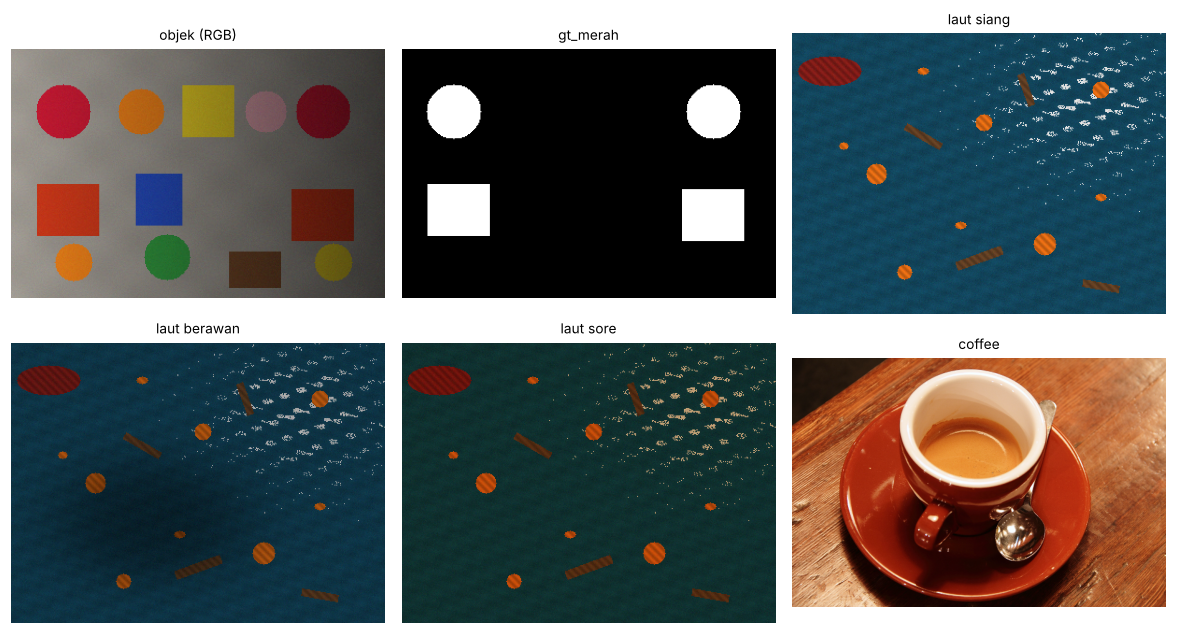

In [1]:
# Sel persiapan — jalankan tanpa diubah
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data, color

plt.rcParams['figure.dpi'] = 110
print('NumPy', np.__version__, '| OpenCV', cv2.__version__)

"""Pembangkit citra uji sintetis Sub-CPMK-4 (benih acak tetap, hanya NumPy).

Semua citra dikembalikan sebagai RGB uint8 (urutan R, G, B). Untuk OpenCV gunakan
cv2.cvtColor(img, cv2.COLOR_RGB2...) atau ubah dulu ke BGR.
Model pencahayaan sengaja disederhanakan: perkalian langsung pada nilai piksel tersandi.
"""
import numpy as np

BENIH = 2027


def _grid(h, w):
    return np.mgrid[0:h, 0:w].astype(np.float64)


def _ke_uint8(x):
    return np.clip(np.floor(255 * x + 0.5), 0, 255).astype(np.uint8)


def _cakram(yy, xx, cy, cx, r):
    return (yy - cy) ** 2 + (xx - cx) ** 2 <= r ** 2


def _kotak(yy, xx, y0, x0, y1, x1):
    return (yy >= y0) & (yy < y1) & (xx >= x0) & (xx < x1)


# ---------------------------------------------------------------- adegan objek berwarna
WARNA_OBJEK = {
    "merah_tua":  (0.78, 0.10, 0.20),   # hue ≈ 351° (sisi magenta dari merah)
    "merah_bata": (0.80, 0.22, 0.10),   # hue ≈ 10°
    "jingga":     (0.92, 0.50, 0.10),
    "kuning":     (0.90, 0.80, 0.15),
    "hijau":      (0.20, 0.60, 0.25),
    "biru":       (0.15, 0.30, 0.75),
    "cokelat":    (0.45, 0.28, 0.16),
    "merah_muda": (0.85, 0.62, 0.66),
}


def objek_warna(rng, h=240, w=360, gelap_kanan=0.35, sigma=0.010):
    """Delapan jenis objek di atas latar netral, pencahayaan menurun linear ke kanan.

    Mengembalikan (citra RGB uint8, masker kebenaran objek merah, peta pencahayaan).
    Objek merah: dua di sisi terang (kiri) dan dua di sisi gelap (kanan).
    """
    yy, xx = _grid(h, w)
    img = np.empty((h, w, 3))
    img[...] = (0.62, 0.60, 0.57)
    img += 0.015 * np.sin(yy / 9.0)[..., None] * np.cos(xx / 13.0)[..., None]
    gt = np.zeros((h, w), bool)
    letak = [  # (warna, bentuk, parameter, merah?)
        ("merah_tua", "c", (60, 50, 26), True), ("merah_bata", "k", (130, 25, 180, 85), True),
        ("merah_tua", "c", (60, 300, 26), True), ("merah_bata", "k", (135, 270, 185, 330), True),
        ("jingga", "c", (60, 125, 22), False), ("kuning", "k", (35, 165, 85, 215), False),
        ("hijau", "c", (200, 150, 22), False), ("biru", "k", (120, 120, 170, 165), False),
        ("cokelat", "k", (195, 210, 230, 260), False), ("merah_muda", "c", (60, 245, 20), False),
        ("jingga", "c", (205, 60, 18), False), ("kuning", "c", (205, 310, 18), False),
    ]
    for nama, bentuk, p, merah in letak:
        m = _cakram(yy, xx, *p) if bentuk == "c" else _kotak(yy, xx, *p)
        img[m] = WARNA_OBJEK[nama]
        if merah:
            gt |= m
    cahaya = 1.0 - (1.0 - gelap_kanan) * xx / (w - 1)
    img = img * cahaya[..., None] + rng.normal(0, sigma, img.shape)
    return _ke_uint8(img), gt, cahaya


# ---------------------------------------------------------------- adegan perairan (SAR)
RAKIT = (0.95, 0.45, 0.08)        # jingga keselamatan (sekoci/rompi)
KAYU = (0.42, 0.27, 0.15)         # puing kayu: corak dekat jingga, gelap, kurang pekat
LAMBUNG = (0.55, 0.12, 0.10)      # cat lambung bawah air (merah tua)
LAUT = (0.07, 0.27, 0.36)


def _geometri_perairan(rng, h, w):
    """Geometri tetap (gelombang, kilau, objek) yang sama untuk semua kondisi cahaya."""
    yy, xx = _grid(h, w)
    gel = (0.55 * np.sin(2 * np.pi * (yy / 23.0 + xx / 61.0)) + 0.35 * np.sin(2 * np.pi * (yy / 11.0 - xx / 37.0))
           + 0.25 * np.sin(2 * np.pi * (xx / 17.0 + yy / 53.0)))
    tekstur = 1.0 + 0.10 * gel / 1.15 + rng.normal(0, 0.03, (h, w))
    # kilau matahari: bercak terang di kanan atas, dekat puncak gelombang
    pusat_kilau = np.exp(-(((yy - 70) / 55.0) ** 2 + ((xx - 310) / 70.0) ** 2))
    kilau = (gel > 0.55) & (rng.random((h, w)) < 0.9 * pusat_kilau)
    obj = {}
    rakit = [(150, 90, 11), (95, 205, 9), (225, 270, 12), (255, 120, 8), (60, 330, 9)]
    rompi = [(175, 330, 4, 6), (205, 180, 4, 6), (120, 55, 4, 5), (40, 140, 4, 6)]
    m_rakit = np.zeros((h, w), bool)
    for cy, cx, r in rakit:
        m_rakit |= _cakram(yy, xx, cy, cx, r)
    for cy, cx, a, b in rompi:
        m_rakit |= ((yy - cy) / a) ** 2 + ((xx - cx) / b) ** 2 <= 1
    m_kayu = np.zeros((h, w), bool)
    for cy, cx, dl, dw, t in [(110, 140, 22, 4, 30), (240, 200, 26, 5, -20), (60, 250, 18, 4, 70), (270, 330, 20, 4, 10)]:
        tr = np.deg2rad(t)
        u, v = (xx - cx) * np.cos(tr) + (yy - cy) * np.sin(tr), -(xx - cx) * np.sin(tr) + (yy - cy) * np.cos(tr)
        m_kayu |= (np.abs(u) <= dl) & (np.abs(v) <= dw)
    m_lambung = ((yy - 40) / 16.0) ** 2 + ((xx - 40) / 34.0) ** 2 <= 1
    obj.update(rakit=m_rakit & ~m_lambung, kayu=m_kayu & ~m_rakit, lambung=m_lambung, kilau=kilau & ~m_rakit & ~m_kayu & ~m_lambung)
    rona = 0.88 + 0.12 * np.cos(2 * np.pi * (yy - xx) / 9.0)        # bayangan lipatan di permukaan objek
    return yy, xx, tekstur, obj, rona


def perairan(rng, kondisi="siang", h=300, w=400, sigma=0.010):
    """Citra udara permukaan laut pascakecelakaan: rakit/rompi jingga, puing kayu, lambung terbalik, kilau.

    kondisi: 'siang' (cahaya putih merata), 'berawan' (redup 0,75 + bayangan awan 0,45),
             'sore' (cahaya hangat: kanal dikali (1,00; 0,82; 0,60) × 0,85).
    Geometri sama untuk semua kondisi (benih geometri tetap); derau berbeda per kondisi.
    Mengembalikan (citra RGB uint8, masker kebenaran rakit/rompi, kamus masker lain).
    """
    yy, xx, tekstur, obj, rona = _geometri_perairan(np.random.default_rng(BENIH + 1), h, w)
    img = np.empty((h, w, 3))
    img[...] = LAUT
    img *= tekstur[..., None]
    img[obj["kilau"]] = 0.80 + 0.15 * rng.random((obj["kilau"].sum(), 1))
    for nama, warna in (("lambung", LAMBUNG), ("kayu", KAYU), ("rakit", RAKIT)):
        m = obj[nama]
        img[m] = np.array(warna) * rona[m][:, None]
    if kondisi == "siang":
        cahaya = np.ones((h, w, 3))
    elif kondisi == "berawan":
        awan = np.exp(-(((yy - 190) / 70.0) ** 2 + ((xx - 150) / 110.0) ** 2) ** 1.5)
        cahaya = np.repeat((0.75 * (1 - 0.40 * awan / awan.max()))[..., None], 3, axis=2)
    elif kondisi == "sore":
        cahaya = np.ones((h, w, 3)) * np.array([1.00, 0.82, 0.60]) * 0.85
    else:
        raise ValueError(kondisi)
    img = img * cahaya + rng.normal(0, sigma, img.shape)
    return _ke_uint8(img), obj["rakit"], obj


def bangkitkan_semua():
    rng = np.random.default_rng(BENIH)
    objek, gt_merah, _ = objek_warna(rng)
    hasil = {"objek": objek, "gt_merah": gt_merah}
    for k in ("siang", "berawan", "sore"):
        im, gt, obj = perairan(rng, k)
        hasil["laut_" + k] = im
    hasil["gt_rakit"] = gt
    hasil["m_kayu"], hasil["m_lambung"], hasil["m_kilau"] = obj["kayu"], obj["lambung"], obj["kilau"]
    return hasil

def tampil(daftar, judul=None, kolom=None, tinggi=3.0, cmap=None):
    n = len(daftar); kolom = kolom or n; baris = int(np.ceil(n / kolom))
    fig, ax = plt.subplots(baris, kolom, figsize=(3.6 * kolom, tinggi * baris)); ax = np.atleast_1d(ax).ravel()
    for a in ax: a.axis('off')
    for a, im, t in zip(ax, daftar, judul or [''] * n):
        a.imshow(im, cmap=cmap if np.ndim(im) == 2 else None); a.set_title(t, fontsize=9)
    plt.tight_layout(); plt.show()

def beda_hue(h1, h2):
    d = np.abs(np.asarray(h1, float) - np.asarray(h2, float)) % 360.0
    return np.minimum(d, 360.0 - d)

def rerata_hue(h):
    t = np.radians(h); return float(np.degrees(np.arctan2(np.sin(t).mean(), np.cos(t).mean())) % 360)

def std_melingkar(h):
    t = np.radians(h); R = np.hypot(np.cos(t).mean(), np.sin(t).mean())
    return float(np.degrees(np.sqrt(-2 * np.log(max(R, 1e-12)))))

def nilai(pred, gt):
    pred, gt = pred.astype(bool), gt.astype(bool); tp = (pred & gt).sum()
    k = cv2.connectedComponents(pred.astype(np.uint8), connectivity=8)[0] - 1
    return dict(iou=round(float(tp / max((pred | gt).sum(), 1)), 3), presisi=round(float(tp / max(pred.sum(), 1)), 3),
                recall=round(float(tp / max(gt.sum(), 1)), 3), komponen=int(k))

def psnr(a, b):
    mse = np.mean((a.astype(float) - b.astype(float)) ** 2)
    return float('inf') if mse == 0 else float(10 * np.log10(255 ** 2 / mse))

C = bangkitkan_semua()
objek, gt_merah = C['objek'], C['gt_merah']
laut = {k: C['laut_' + k] for k in ('siang', 'berawan', 'sore')}
gt_rakit, m_kayu, m_lambung, m_kilau = C['gt_rakit'], C['m_kayu'], C['m_lambung'], C['m_kilau']
kopi = data.coffee()
YY, XX = np.mgrid[0:240, 0:360]          # koordinat baris, kolom citra objek
tampil([objek, gt_merah, laut['siang'], laut['berawan'], laut['sore'], kopi],
       ['objek (RGB)', 'gt_merah', 'laut siang', 'laut berawan', 'laut sore', 'coffee'], kolom=3, cmap='gray')

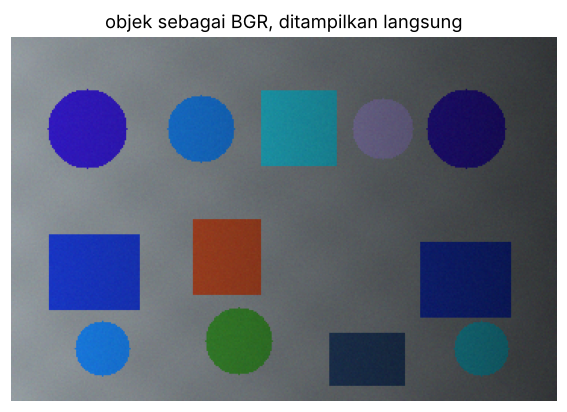

Piksel objek[60, 50] RGB (R, G, B): [181  22  47]
Piksel objek[60, 50] BGR (B, G, R): [ 47  22 181]


In [2]:
# TODO 0.1 — Jebakan BGR. cv2.imread menghasilkan urutan B, G, R. Tirukan dengan cv2.cvtColor(objek, cv2.COLOR_RGB2BGR),
#            tampilkan hasilnya LANGSUNG dengan plt.imshow, lalu cetak nilai piksel objek[60, 50] dan versi BGR-nya.
bgr = cv2.cvtColor(objek, cv2.COLOR_RGB2BGR)
plt.imshow(bgr); plt.title('objek sebagai BGR, ditampilkan langsung'); plt.axis('off'); plt.show()
print('Piksel objek[60, 50] RGB (R, G, B):', objek[60, 50])
print('Piksel objek[60, 50] BGR (B, G, R):', bgr[60, 50])


## Bagian 1 &mdash; Konversi dari definisi (25 menit)

**HSI menurut Gonzalez** (RGB dinormalisasi ke [0, 1]):

$$\theta = \cos^{-1}\left\{\frac{\tfrac12[(R-G)+(R-B)]}{[(R-G)^2+(R-B)(G-B)]^{1/2}}\right\},\quad H = \begin{cases}\theta & B \le G\\ 360-\theta & B > G\end{cases}\quad \text{(6-16, 6-17)}$$

$$S = 1 - \frac{3}{R+G+B}\min(R,G,B) \quad\text{(6-18)},\qquad I = \tfrac13(R+G+B)\quad\text{(6-19)}$$

Kebalikannya dihitung per sektor 120&deg; (Eq. 6-20 s.d. 6-30). Pada sektor RG (0 &le; H &lt; 120&deg;): $B = I(1-S)$, $R = I[1 + S\cos H/\cos(60^\circ - H)]$, $G = 3I - (R+B)$.
Sektor GB dan BR memakai rumus yang sama setelah H dikurangi 120&deg; atau 240&deg;, dengan peran R, G, B digeser.

**HSV (Smith, 1978; dipakai OpenCV)**: $V = \max(R,G,B)$, $S = (V - \min)/V$, H dihitung per sektor 60&deg;. Pada citra 8-bit OpenCV menyimpan **H/2** (0&ndash;179), S&times;255, V&times;255.

In [3]:
# TODO 1.1 — Implementasikan rgb_ke_hsi dari Eq. 6-16 s.d. 6-19. Masukan uint8 atau float [0, 1]; keluaran H (derajat), S, I.
#            Tambahkan bilangan kecil pada penyebut (catatan kaki Gonzalez) dan set H = 0 bila S = 0.
def rgb_ke_hsi(rgb):
    x = np.asarray(rgb)
    x = x / 255.0 if x.dtype == np.uint8 else x.astype(np.float64)
    R, G, B = x[..., 0], x[..., 1], x[..., 2]
    eps = 1e-10
    theta = np.degrees(np.arccos(np.clip(0.5 * ((R - G) + (R - B)) / (np.sqrt((R - G) ** 2 + (R - B) * (G - B)) + eps), -1, 1)))  # Eq. 6-16
    H = np.where(B <= G, theta, 360 - theta)                                   # Eq. 6-17
    S = np.where((R == G) & (G == B), 0.0, 1 - 3 * np.minimum(np.minimum(R, G), B) / (R + G + B + eps))  # Eq. 6-18
    return np.where(S == 0, 0.0, H), S, (R + G + B) / 3                        # Eq. 6-19

H, S, I = rgb_ke_hsi(np.array([[[0.8, 0.5, 0.2]]]))
print('HSI (0.8, 0.5, 0.2):', H[0, 0], S[0, 0], I[0, 0])   # bandingkan dengan hitung tangan di kelas
print('Hasil hitung tangan Gonzalez : H = 30 derajat, S = 0.6, I = 0.5')

HSI (0.8, 0.5, 0.2): 30.000000019098586 0.6000000000266665 0.5
Hasil hitung tangan Gonzalez : H = 30 derajat, S = 0.6, I = 0.5


In [4]:
# TODO 1.2 — Implementasikan hsi_ke_rgb (Eq. 6-20 s.d. 6-30) untuk ketiga sektor.
#            Uji: konversi `objek` ke HSI lalu kembali; laporkan selisih maksimum (skala 0..1).
def hsi_ke_rgb(H, S, I):
    H = np.asarray(H, float) % 360; S = np.asarray(S, float); I = np.asarray(I, float)
    k = (H // 120).astype(int); h = np.radians(H - 120 * k)
    x = I * (1 - S); y = I * (1 + S * np.cos(h) / np.cos(np.radians(60) - h)); z = 3 * I - (x + y)
    pilih = lambda a, b, c: np.select([k == 0, k == 1], [a, b], c)             # sektor RG, GB, BR
    return np.stack([pilih(y, x, z), pilih(z, y, x), pilih(x, z, y)], axis=-1)
Ho, So, Io = rgb_ke_hsi(objek)
balik = hsi_ke_rgb(Ho, So, Io)
print('Selisih maksimum RGB -> HSI -> RGB (skala 0..1) :', np.abs(balik - objek / 255.0).max())

Selisih maksimum RGB -> HSI -> RGB (skala 0..1) : 8.914582882449396e-06


In [5]:
# TODO 1.3 — Implementasikan rgb_ke_hsv (heksakerucut). Bandingkan dengan cv2.cvtColor(objek, cv2.COLOR_RGB2HSV):
#            ingat OpenCV 8-bit menyimpan H/2 dan S×255. Laporkan selisih hue maksimum (derajat) dan penyebabnya.
#            Lalu cetak piksel (204, 128, 51) dalam tiga bentuk: HSI Anda, HSV Anda, dan HSV 8-bit OpenCV.
def rgb_ke_hsv(rgb):
    x = np.asarray(rgb)
    x = x / 255.0 if x.dtype == np.uint8 else x.astype(np.float64)
    R, G, B = x[..., 0], x[..., 1], x[..., 2]
    V = x.max(-1); d = V - x.min(-1); dd = np.where(d == 0, 1, d)
    H = 60 * np.where(V == R, ((G - B) / dd) % 6, np.where(V == G, (B - R) / dd + 2, (R - G) / dd + 4))
    return np.where(d == 0, 0.0, H), d / np.where(V == 0, 1, V), V
Hm, Sm, Vm = rgb_ke_hsv(objek)
hv_cv = cv2.cvtColor(objek, cv2.COLOR_RGB2HSV)
print('Selisih hue maksimum implementasi vs OpenCV (derajat):', beda_hue(Hm, hv_cv[..., 0] * 2.0).max())
p = np.array([[[204, 128, 51]]], dtype=np.uint8)
print('Piksel (204, 128, 51):')
print('  HSI              :', [float(v[0, 0]) for v in rgb_ke_hsi(p)])
print('  HSV              :', [float(v[0, 0]) for v in rgb_ke_hsv(p)])
print('  HSV 8-bit OpenCV :', cv2.cvtColor(p, cv2.COLOR_RGB2HSV)[0, 0])

Selisih hue maksimum implementasi vs OpenCV (derajat): 1.0434782608695627
Piksel (204, 128, 51):
  HSI              : [30.216206402680015, 0.6005221932380853, 0.5006535947712418]
  HSV              : [30.19607843137254, 0.7500000000000001, 0.8]
  HSV 8-bit OpenCV : [ 15 191 204]


In [6]:
# TODO 1.4 — Lab. (a) Hitung cv2.cvtColor(p, cv2.COLOR_RGB2Lab) untuk p = (204, 128, 51) dan kembalikan ke L*, a*, b* sebenarnya
#            (OpenCV 8-bit: L×255/100, a+128, b+128). (b) Bandingkan dengan skimage.color.rgb2lab(p).
#            (c) Mengapa jarak Euclid pada keluaran 8-bit OpenCV BUKAN ΔE*ab? Tunjukkan dengan dua warna yang hanya berbeda L*.
p = np.array([[[204, 128, 51]]], dtype=np.uint8)
lab8 = cv2.cvtColor(p, cv2.COLOR_RGB2Lab)[0, 0].astype(float)
lab_cv = np.array([lab8[0] * 100 / 255, lab8[1] - 128, lab8[2] - 128])
lab_sk = color.rgb2lab(p)[0, 0]
print('Lab 8-bit OpenCV mentah :', lab8)
print('Dikembalikan (L*, a*, b*):', lab_cv, '| skimage:', lab_sk, '| selisih:', np.abs(lab_cv - lab_sk))
dua = np.array([[[100, 100, 100], [150, 150, 150]]], dtype=np.uint8)
d8 = np.linalg.norm(np.diff(cv2.cvtColor(dua, cv2.COLOR_RGB2Lab)[0].astype(float), axis=0))
dE = np.linalg.norm(np.diff(color.rgb2lab(dua)[0], axis=0))
print(f'Dua abu-abu beda L*: jarak Euclid 8-bit = {d8:.4f}, Delta E*ab sebenarnya = {dE:.4f}, nisbah = {d8 / dE:.4f}')

Lab 8-bit OpenCV mentah : [154. 151. 180.]
Dikembalikan (L*, a*, b*): [60.39215686 23.         52.        ] | skimage: [60.35390674 23.09295659 51.96147967] | selisih: [0.03825013 0.09295659 0.03852033]
Dua abu-abu beda L*: jarak Euclid 8-bit = 50.0000, Delta E*ab sebenarnya = 19.7076, nisbah = 2.5371


In [7]:
# [Pengayaan] TODO 1.5 — Implementasikan Lab dari definisi (Eq. 6-31 s.d. 6-34) dengan linearisasi sRGB dan matriks sRGB→XYZ (D65).
#            Bandingkan dengan skimage; lalu ulangi TANPA linearisasi. Berapa selisih maksimumnya? Apa artinya bagi rumus di dokumentasi?
def lab_definisi(rgb, lin=True):
    c = np.asarray(rgb) / 255.0
    if lin: c = np.where(c <= 0.04045, c / 12.92, ((c + 0.055) / 1.055) ** 2.4)
    M = np.array([[0.4124564, 0.3575761, 0.1804375], [0.2126729, 0.7151522, 0.0721750], [0.0193339, 0.1191920, 0.9503041]])
    t = (c @ M.T) / np.array([0.95047, 1.0, 1.08883])
    f_ = np.where(t > 0.008856, np.cbrt(t), 7.787 * t + 16 / 116)
    return np.stack([116 * f_[..., 1] - 16, 500 * (f_[..., 0] - f_[..., 1]), 200 * (f_[..., 1] - f_[..., 2])], -1)
for nama, lin in [('dengan linearisasi', True), ('tanpa linearisasi', False)]:
    print(f'Selisih maks vs skimage, {nama:19s}: L*, a*, b* =', np.abs(lab_definisi(objek, lin) - color.rgb2lab(objek)).max(axis=(0, 1)))

Selisih maks vs skimage, dengan linearisasi : L*, a*, b* = [0.00046441 0.00243032 0.00324309]
Selisih maks vs skimage, tanpa linearisasi  : L*, a*, b* = [30.61299142 23.75950702 25.39410816]


**Analisis 1.** (a) Tuliskan nilai HSI, HSV, dan HSV 8-bit OpenCV untuk piksel (204, 128, 51). Mengapa S berbeda antara HSI dan HSV padahal H sama? (b) Dari mana selisih hue &asymp;1&deg; antara implementasi Anda dan OpenCV? (c) Apa akibatnya bila ambang Lab dirancang dari literatur (L* 0&ndash;100) tetapi diterapkan pada keluaran 8-bit OpenCV?

*Jawaban:*

(a) Untuk piksel (204, 128, 51):
- HSI: H = 30,216206; S = 0,600522; I = 0,500654.
- HSV: H = 30,196078; S = 0,750000; V = 0,800000.
- HSV 8-bit OpenCV: H = 15, S = 191, V = 204.

H hampir sama (±30°) karena sudut warna hanya bergantung pada perbandingan R, G, B, dan perbandingan itu sama di kedua model. S berbeda karena pembaginya berbeda: HSI membagi nilai minimum (0,2) dengan rerata I (0,5007), sehingga S = 1 − 0,2/0,5007 ≈ 0,60; HSV membaginya dengan nilai maksimum V (0,8), sehingga S = 1 − 0,2/0,8 = 0,75.

(b) OpenCV 8-bit menyimpan hue sebagai H/2 dalam bilangan bulat 0–179, jadi resolusinya hanya 2°. Pada piksel di atas, 30,196/2 = 15,098 dibulatkan menjadi 15, yang kembali menjadi 30°. Akibat pembulatan ini, selisih hue maksimum antara `rgb_ke_hsv` dan OpenCV pada citra `objek` adalah 1,043°.

(c) OpenCV 8-bit menyimpan L* × 255/100 serta a* + 128 dan b* + 128. Piksel di atas bernilai L* = 60,39, a* = 23, b* = 52, tetapi tersimpan sebagai (154, 151, 180). Jika ambang dari literatur (L* 0–100) dipakai langsung pada angka 8-bit ini, ambangnya salah skala sehingga masker bergeser atau kosong. Jarak Euclid pada skala 8-bit juga bukan ΔE*ab: dua abu-abu (100) dan (150) memberi jarak 50,0000 pada OpenCV, padahal ΔE*ab sebenarnya 19,7076 (nisbah 2,54).


## Bagian 2 &mdash; Pencahayaan dan derau (20 menit)

Citra `objek` memuat dua cakram **berwarna sama** (merah tua): satu di sisi terang (pusat baris 60, kolom 50; faktor cahaya 0,91) dan satu di sisi gelap (kolom 300; faktor 0,46).

In [8]:
# TODO 2.1 — Untuk cakram kiri dan kanan (jari-jari 20 piksel), hitung rerata R, G, B; H, S, V (HSV Anda); H, S, I (HSI);
#            L*, a*, b*, kroma C* = sqrt(a*² + b*²), dan sudut hue h_ab = atan2(b*, a*). Pakai rerata_hue untuk sudut.
#            Susun tabel: kiri, kanan, dan nisbah kanan/kiri (untuk sudut: selisih derajat).
kiri = (YY - 60) ** 2 + (XX - 50) ** 2 <= 20 ** 2
kanan = (YY - 60) ** 2 + (XX - 300) ** 2 <= 20 ** 2
def statistik(m):
    px = objek[m]; Hv, Sv, Vv = rgb_ke_hsv(px); Hi, Si, Ii = rgb_ke_hsi(px)
    L, a, b = color.rgb2lab(px[None])[0].T
    return {'R': px[:, 0].mean(), 'G': px[:, 1].mean(), 'B': px[:, 2].mean(), 'H (HSV)': rerata_hue(Hv), 'S (HSV)': Sv.mean(), 'V (HSV)': Vv.mean(),
            'H (HSI)': rerata_hue(Hi), 'S (HSI)': Si.mean(), 'I (HSI)': Ii.mean(), 'L*': L.mean(), 'a*': a.mean(), 'b*': b.mean(),
            'C*': np.hypot(a, b).mean(), 'h_ab': rerata_hue(np.degrees(np.arctan2(b, a)) % 360)}
tk, tr = statistik(kiri), statistik(kanan)
print(f'{"besaran":9s} {"kiri":>11s} {"kanan":>11s} {"kanan/kiri":>11s}')
for k in tk:
    sudut = k in ('H (HSV)', 'H (HSI)', 'h_ab')
    print(f'{k:9s} {tk[k]:11.4f} {tr[k]:11.4f} {beda_hue(tk[k], tr[k]) if sudut else tr[k] / tk[k]:11.4f}', '(selisih derajat)' if sudut else '')

besaran          kiri       kanan  kanan/kiri
R            180.9459     90.9761      0.5028 
G             23.2856     11.5959      0.4980 
B             46.3819     23.2959      0.5023 
H (HSV)      351.2212    351.1998      0.0214 (selisih derajat)
S (HSV)        0.8713      0.8724      1.0013 
V (HSV)        0.7096      0.3568      0.5028 
H (HSI)      352.2055    352.1547      0.0508 (selisih derajat)
S (HSI)        0.7215      0.7245      1.0042 
I (HSI)        0.3276      0.1645      0.5022 
L*            38.9825     18.1112      0.4646 
a*            59.7057     35.1554      0.5888 
b*            30.4004     15.8875      0.5226 
C*            67.0154     38.6195      0.5763 
h_ab          26.9708     24.2742      2.6966 (selisih derajat)


In [9]:
# TODO 2.2 — Kapan hue tidak bisa dipercaya? Bangkitkan 20000 piksel ber-hue 20° dengan S dan V tertentu,
#            tambahkan derau Gaussian σ = 3 aras per kanal, hitung simpangan baku melingkar hue (std_melingkar).
#            Lakukan untuk S ∈ {0.05, 0.1, 0.2, 0.4, 0.8} (V = 0.8), lalu V ∈ {0.05, 0.1, 0.2, 0.4, 0.8} (S = 0.8).
rng = np.random.default_rng(7)      # jangan diubah agar angka sebanding
def piksel_uji(sat, val, n=20000, sigma=3.0):
    dasar = np.array([1.0, 1 - sat * (1 - 20 / 60), 1 - sat]) * val
    return np.clip(np.floor(dasar * 255 + rng.normal(0, sigma, (n, 3)) + 0.5), 0, 255).astype(np.uint8)[None]
print('Simpangan baku melingkar hue (derajat):')
for sat in (0.05, 0.1, 0.2, 0.4, 0.8): print(f'  S = {sat:4.2f} (V = 0.8): {std_melingkar(rgb_ke_hsv(piksel_uji(sat, 0.8))[0].ravel()):.4f}')
for val in (0.05, 0.1, 0.2, 0.4, 0.8): print(f'  V = {val:4.2f} (S = 0.8): {std_melingkar(rgb_ke_hsv(piksel_uji(0.8, val))[0].ravel()):.4f}')

Simpangan baku melingkar hue (derajat):
  S = 0.05 (V = 0.8): 26.1787
  S = 0.10 (V = 0.8): 11.8228
  S = 0.20 (V = 0.8): 5.6591
  S = 0.40 (V = 0.8): 2.8112
  S = 0.80 (V = 0.8): 1.3803
  V = 0.05 (S = 0.8): 26.3148
  V = 0.10 (S = 0.8): 11.5988
  V = 0.20 (S = 0.8): 5.6280
  V = 0.40 (S = 0.8): 2.7820
  V = 0.80 (S = 0.8): 1.3834


**Analisis 2.** (a) Besaran mana yang **tetap** (nisbah &asymp; 1 atau selisih &asymp; 0&deg;) dan mana yang ikut turun &asymp;50 %? Apakah a* dan b* termasuk yang tetap? (b) Pada S atau V berapa simpangan baku hue melebihi 10&deg;? Mengapa S dan V memberi angka hampir sama (petunjuk: penyebut rumus hue adalah maks &minus; min)? (c) Rumuskan syarat praktis sebelum Anda memakai ambang hue.

*Jawaban:*

(a) Yang tetap: hue (selisih HSV 0,0214° dan HSI 0,0508°) dan saturasi (nisbah HSV 1,0013, HSI 1,0042). Yang turun ±50 %: R (0,5028), G (0,4980), B (0,5023), V (0,5028), dan I (0,5022), karena cahaya sisi kanan memang 0,46/0,91 ≈ 0,5 kali sisi kiri. L* juga turun (0,4646). a* dan b* tidak termasuk yang tetap: nisbahnya 0,5888 dan 0,5226, dan kroma C* ikut turun (0,5763). Yang relatif tetap hanya sudut h_ab (selisih 2,6966°).

(b) Simpangan baku hue melebihi 10° pada S = 0,05 (26,1787°) dan S = 0,10 (11,8228°), serta pada V = 0,05 (26,3148°) dan V = 0,10 (11,5988°). Pada 0,20 sudah turun menjadi 5,6591° (S) dan 5,6280° (V). Angka S dan V hampir sama karena penyebut rumus hue adalah maks − min = V × S. Yang menentukan adalah hasil kali V × S: baik S kecil maupun V kecil membuat selisih antarkanal kecil, sehingga derau σ = 3 aras mengacaukan sudut.

(c) Hue hanya boleh dipakai sebagai ambang bila S dan V cukup besar, misalnya S ≥ 0,2 dan V ≥ 0,2 (simpangan baku < 6°). Di bawah 0,1 hue tidak dapat dipercaya, sehingga aturan hue harus selalu disertai batas minimum S dan V.


## Bagian 3 &mdash; Pemrosesan citra berwarna (20 menit)

Gonzalez (§6.5) memperingatkan bahwa ekualisasi histogram setiap kanal RGB secara terpisah menghasilkan warna keliru; yang masuk akal adalah meratakan **intensitas** dan membiarkan hue. Kita ukur.

cara                      geser hue   rerata I   rerata S
redup (sebelum)              0.0000     0.2163     0.7773


(a) setiap kanal RGB        67.5402     0.4629     0.3153

(b) kanal I (HSI)            6.1783     0.4423     0.7446
(c) kanal V (HSV)            0.5240     0.2702     0.7843
(d) kanal L* (Lab)           2.7838     0.4488     0.3500
Piksel HSI di luar [0, 1] sebelum clip pada (b): 59.5471 persen


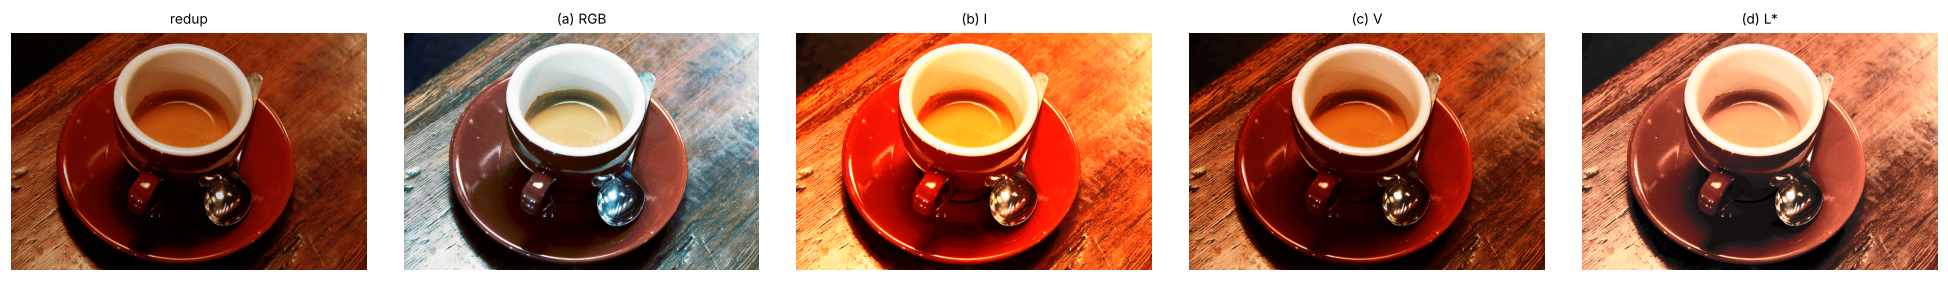

In [10]:
# TODO 3.1 — Buat citra redup: redup = 0.85 · (kopi/255)^1.8 (bulatkan ke uint8). Lakukan ekualisasi histogram dengan empat cara:
#   (a) setiap kanal RGB terpisah; (b) kanal I (HSI Anda), kembalikan dengan hsi_ke_rgb lalu clip;
#   (c) kanal V dari cv2 HSV; (d) kanal L* dari Lab (pakai skimage rgb2lab/lab2rgb, L* diskala ke 0..255 untuk equalizeHist).
# Ukur terhadap `redup`: rerata pergeseran hue (beda_hue, hanya piksel S > 0,2 dan V > 0,08), rerata I, rerata S,
# dan untuk (b) persentase piksel yang keluar dari [0, 1] sebelum clip.
redup = np.clip(np.floor(255 * 0.85 * (kopi / 255.0) ** 1.8 + 0.5), 0, 255).astype(np.uint8)
Hr, Sr, Vr = rgb_ke_hsv(redup); mask = (Sr > 0.2) & (Vr > 0.08)
Hi0, Si0, Ii0 = rgb_ke_hsi(redup)
u8 = lambda x: np.clip(np.floor(255 * x + 0.5), 0, 255).astype(np.uint8)
eq = cv2.equalizeHist
hasil_a = np.stack([eq(redup[..., k]) for k in range(3)], -1)                       # (a) setiap kanal RGB
rgb_b = hsi_ke_rgb(Hi0, Si0, eq(u8(Ii0)) / 255.0)                                    # (b) kanal I (HSI)
luar = np.any((rgb_b < 0) | (rgb_b > 1), axis=-1).mean() * 100
hasil_b = u8(np.clip(rgb_b, 0, 1))
hsv_c = cv2.cvtColor(redup, cv2.COLOR_RGB2HSV); hsv_c[..., 2] = eq(hsv_c[..., 2])   # (c) kanal V (OpenCV HSV)
hasil_c = cv2.cvtColor(hsv_c, cv2.COLOR_HSV2RGB)
lab_d = color.rgb2lab(redup); lab_d[..., 0] = eq(u8(lab_d[..., 0] / 100)) / 255.0 * 100  # (d) kanal L* (skimage)
hasil_d = u8(color.lab2rgb(lab_d))
print(f'{"cara":24s} {"geser hue":>10s} {"rerata I":>10s} {"rerata S":>10s}')
print(f'{"redup (sebelum)":24s} {0:10.4f} {Ii0.mean():10.4f} {Si0.mean():10.4f}')
for nama, im in [('(a) setiap kanal RGB', hasil_a), ('(b) kanal I (HSI)', hasil_b), ('(c) kanal V (HSV)', hasil_c), ('(d) kanal L* (Lab)', hasil_d)]:
    _, Sx, Ix = rgb_ke_hsi(im)
    print(f'{nama:24s} {beda_hue(Hr[mask], rgb_ke_hsv(im)[0][mask]).mean():10.4f} {Ix.mean():10.4f} {Sx.mean():10.4f}')
print(f'Piksel HSI di luar [0, 1] sebelum clip pada (b): {luar:.4f} persen')
tampil([redup, hasil_a, hasil_b, hasil_c, hasil_d], ['redup', '(a) RGB', '(b) I', '(c) V', '(d) L*'], kolom=5, tinggi=2.5)

In [11]:
# [Pengayaan] TODO 3.2 — Subsampling krominans. Ubah kopi ke YCbCr (cv2.COLOR_RGB2YCrCb — perhatikan urutan Y, Cr, Cb!),
#            perkecil Cr dan Cb 2× dan 4× (cv2.resize INTER_AREA, lalu perbesar INTER_LINEAR), kembalikan ke RGB, hitung PSNR.
#            Bandingkan dengan memperkecil R, G, B sama besar sehingga jumlah data sama (faktor per sumbu √(3/(1 + 2/f²))).
ycc = cv2.cvtColor(kopi, cv2.COLOR_RGB2YCrCb); hh, ww = kopi.shape[:2]
turun_naik = lambda c, s: cv2.resize(cv2.resize(c, (int(round(ww / s)), int(round(hh / s))), interpolation=cv2.INTER_AREA), (ww, hh), interpolation=cv2.INTER_LINEAR)
print(f'{"faktor":>6s} {"PSNR Cr,Cb (dB)":>16s} {"PSNR R,G,B (dB)":>16s}')
for fk in (2, 4):
    y2 = np.stack([ycc[..., 0], turun_naik(ycc[..., 1], fk), turun_naik(ycc[..., 2], fk)], -1)
    g = np.sqrt(3 / (1 + 2 / fk ** 2))
    rgb2 = np.stack([turun_naik(kopi[..., k], g) for k in range(3)], -1)
    print(f'{fk:5d}x {psnr(kopi, cv2.cvtColor(y2, cv2.COLOR_YCrCb2RGB)):16.4f} {psnr(kopi, rgb2):16.4f}')

faktor  PSNR Cr,Cb (dB)  PSNR R,G,B (dB)
    2x          39.6881          30.2103
    4x          36.2500          29.3243


**Analisis 3.** (a) Cara mana yang paling merusak hue, dan mengapa? (b) Mengapa ekualisasi kanal I menghasilkan banyak piksel di luar gamut, dan apa akibat pemotongan (clip) terhadap hue? (c) Ekualisasi V menjaga hue hampir sempurna tetapi kecerahannya naik paling sedikit. Jelaskan dari definisi V. (d) Tidak ada cara yang menang di semua ukuran. Mana yang Anda pilih untuk citra kamera kapal yang redup, dan apa harganya?

*Jawaban:*

(a) Ekualisasi setiap kanal RGB (cara a) paling merusak hue: pergeseran 67,5402°, dibandingkan 6,1783° (I), 0,5240° (V), dan 2,7838° (L*). Tiap kanal diratakan dengan histogramnya sendiri, sehingga perbandingan R : G : B berubah dan warnanya ikut berubah. Saturasi juga turun dari 0,7773 menjadi 0,3153.

(b) Ekualisasi I menaikkan rerata I dari 0,2163 menjadi 0,4423 sambil mempertahankan H dan S. Warna yang sangat jenuh tidak dapat memiliki intensitas setinggi itu di dalam kubus RGB, sehingga 59,5471 % piksel keluar dari [0, 1] saat dikonversi balik. Clip memotong kanal yang lebih dari 1, sehingga perbandingan R : G : B berubah; akibatnya hue bergeser 6,1783° dan S turun menjadi 0,7446.

(c) V = maks(R, G, B). Mengubah V dengan H dan S tetap berarti ketiga kanal dikalikan faktor yang sama, sehingga perbandingan kanal (hue dan saturasi) hampir tidak berubah (pergeseran hue 0,5240°, S 0,7773 menjadi 0,7843). Tetapi V hanya mewakili kanal terbesar, sementara I adalah rerata ketiga kanal, sehingga rerata I hanya naik dari 0,2163 menjadi 0,2702, paling kecil dibanding cara lain (0,4423 dan 0,4488).

(d) Untuk citra kamera kapal yang redup dan tujuannya mendeteksi warna, saya memilih ekualisasi V karena hue dan saturasinya paling terjaga (0,5240°). Harganya, citra tetap relatif gelap (I = 0,2702). Bila yang dibutuhkan citra yang lebih terang untuk dilihat manusia, ekualisasi L* (I = 0,4488) lebih cocok, dengan harga hue bergeser 2,7838° dan S turun menjadi 0,3500 (warna pudar).


## Bagian 4 &mdash; Segmentasi berbasis warna (30 menit)

Tugas: temukan keempat objek merah pada `objek` (dua merah tua, hue &asymp;351&deg;; dua merah bata, hue &asymp;10&deg;). **Sampel latih hanya boleh diambil dari sisi terang** (kolom &lt; 120), kecuali bila diminta lain. Penilaian memakai `gt_merah` dan fungsi `nilai`.

Jarak Euclid (Eq. 6-48): $D(\mathbf z, \mathbf a) = \lVert \mathbf z - \mathbf a\rVert$. Jarak Mahalanobis (Eq. 6-49): $D(\mathbf z, \mathbf a) = [(\mathbf z - \mathbf a)^T \mathbf C^{-1}(\mathbf z - \mathbf a)]^{1/2}$. Ambang $D_0$ = persentil 99 jarak sampel latih ke reratanya.

In [12]:
# TODO 4.1 — Aturan RGB tetap dari contoh Blok 1: R > 150, G < 80, B < 80. Nilai dengan nilai(pred, gt_merah).
latih = gt_merah & (XX < 120)
f = objek.reshape(-1, 3).astype(float)
hasil = {}
masker = {}
pred = (objek[..., 0] > 150) & (objek[..., 1] < 80) & (objek[..., 2] < 80)
masker['RGB aturan tetap'] = pred; hasil['RGB aturan tetap'] = nilai(pred, gt_merah)
print('RGB aturan tetap:', hasil['RGB aturan tetap'])

RGB aturan tetap: {'iou': 0.5, 'presisi': 1.0, 'recall': 0.5, 'komponen': 2}


In [13]:
# TODO 4.2 — (a) Bola Euclid (Eq. 6-48) dan (b) elipsoid Mahalanobis (Eq. 6-49) dari sampel `latih`.
#            (c) Ulangi Mahalanobis dengan sampel latih ditambah cakram merah tua sisi gelap (pusat 60, 300; r = 20).
def euclid(fitur, sampel):
    a = sampel.mean(0)
    return np.linalg.norm(fitur - a, axis=1) <= np.percentile(np.linalg.norm(sampel - a, axis=1), 99)   # Eq. 6-48
def mahalanobis(fitur, sampel):
    a = sampel.mean(0); Ci = np.linalg.inv(np.cov(sampel.T))
    D = lambda z: np.sqrt(np.einsum('ij,jk,ik->i', z - a, Ci, z - a))                                    # Eq. 6-49
    return D(fitur) <= np.percentile(D(sampel), 99)
sampel = f[latih.ravel()]
gelap = (YY - 60) ** 2 + (XX - 300) ** 2 <= 20 ** 2
for nama, pred in [('RGB Euclid', euclid(f, sampel)), ('RGB Mahalanobis', mahalanobis(f, sampel)),
                   ('RGB Mahalanobis + sampel gelap', mahalanobis(f, np.vstack([sampel, f[gelap.ravel()]])))]:
    masker[nama] = pred.reshape(objek.shape[:2]); hasil[nama] = nilai(masker[nama], gt_merah); print(nama, ':', hasil[nama])

RGB Euclid : {'iou': 0.495, 'presisi': 1.0, 'recall': 0.495, 'komponen': 2}
RGB Mahalanobis : {'iou': 0.495, 'presisi': 1.0, 'recall': 0.495, 'komponen': 2}
RGB Mahalanobis + sampel gelap : {'iou': 0.978, 'presisi': 1.0, 'recall': 0.978, 'komponen': 4}


In [14]:
# TODO 4.3 — HSV OpenCV 8-bit. Syarat dasar S ≥ 120 dan V ≥ 40. Bandingkan:
#            (a) satu selang H ≤ 10; (b) dua selang H ≤ 10 atau H ≥ 170; (c) dua selang tanpa syarat S.
hv = cv2.cvtColor(objek, cv2.COLOR_RGB2HSV).astype(int)
dasar = (hv[..., 1] >= 120) & (hv[..., 2] >= 40); H8 = hv[..., 0]
for nama, pred in [('HSV satu selang (H <= 10)', dasar & (H8 <= 10)),
                   ('HSV dua selang (H <= 10 atau H >= 170)', dasar & ((H8 <= 10) | (H8 >= 170))),
                   ('HSV dua selang tanpa syarat S', (hv[..., 2] >= 40) & ((H8 <= 10) | (H8 >= 170)))]:
    masker[nama] = pred; hasil[nama] = nilai(pred, gt_merah); print(nama, ':', hasil[nama])

HSV satu selang (H <= 10) : {'iou': 0.569, 'presisi': 0.948, 'recall': 0.587, 'komponen': 141}
HSV dua selang (H <= 10 atau H >= 170) : {'iou': 0.969, 'presisi': 0.969, 'recall': 1.0, 'komponen': 133}
HSV dua selang tanpa syarat S : {'iou': 0.397, 'presisi': 0.397, 'recall': 1.0, 'komponen': 4373}


metode                                      IoU  presisi  recall  komponen
RGB aturan tetap                          0.500    1.000   0.500         2
RGB Euclid                                0.495    1.000   0.495         2
RGB Mahalanobis                           0.495    1.000   0.495         2
RGB Mahalanobis + sampel gelap            0.978    1.000   0.978         4
HSV satu selang (H <= 10)                 0.569    0.948   0.587       141
HSV dua selang (H <= 10 atau H >= 170)    0.969    0.969   1.000       133
HSV dua selang tanpa syarat S             0.397    0.397   1.000      4373
Lab Euclid a*b*                           0.495    1.000   0.495         2
Lab selang h_ab dan kroma                 0.995    1.000   0.995         4


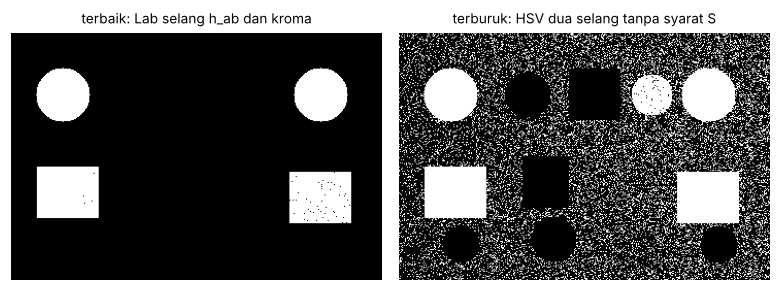

In [15]:
# TODO 4.4 — Lab. (a) Bola Euclid pada bidang a*b* saja (L* diabaikan), sampel `latih`.
#            (b) Selang sudut hue h_ab ≤ 45° atau ≥ 345° dengan kroma C* ≥ 25.
#            Lalu cetak seluruh `hasil` sebagai satu tabel dan tampilkan masker terbaik serta terburuk.
lab_o = color.rgb2lab(objek); ab = lab_o[..., 1:3].reshape(-1, 2)
masker['Lab Euclid a*b*'] = euclid(ab, ab[latih.ravel()]).reshape(objek.shape[:2])
h_ab = np.degrees(np.arctan2(lab_o[..., 2], lab_o[..., 1])) % 360
masker['Lab selang h_ab dan kroma'] = ((h_ab <= 45) | (h_ab >= 345)) & (np.hypot(lab_o[..., 1], lab_o[..., 2]) >= 25)
for k in ('Lab Euclid a*b*', 'Lab selang h_ab dan kroma'): hasil[k] = nilai(masker[k], gt_merah)
print(f'{"metode":40s} {"IoU":>6s} {"presisi":>8s} {"recall":>7s} {"komponen":>9s}')
for k, v in hasil.items(): print(f'{k:40s} {v["iou"]:6.3f} {v["presisi"]:8.3f} {v["recall"]:7.3f} {v["komponen"]:9d}')
terbaik, terburuk = max(hasil, key=lambda k: hasil[k]['iou']), min(hasil, key=lambda k: hasil[k]['iou'])
tampil([masker[terbaik], masker[terburuk]], ['terbaik: ' + terbaik, 'terburuk: ' + terburuk], cmap='gray')

**Analisis 4.** (a) Gonzalez (§6.7) menyatakan segmentasi pada vektor RGB *umumnya* lebih baik daripada HSI, sedangkan banyak tutorial menyatakan sebaliknya. Dengan angka TODO 4.2 dan 4.3, tunjukkan kapan masing-masing benar. (b) Mengapa jarak Euclid pada a*b* gagal sama parahnya dengan RGB, padahal Lab "memisahkan kecerahan"? (c) Mengapa HSV dua selang memberi puluhan komponen walau IoU-nya tinggi, dan dari objek mana komponen palsu itu? (d) Sebutkan satu prasyarat agar jumlah komponen dapat dipakai sebagai ukuran.

*Jawaban:*

(a) Keduanya benar, tergantung sampel latihnya. Bila sampel mencakup kedua sisi cahaya, RGB Mahalanobis memberi IoU 0,978 (presisi 1,000, 4 komponen), lebih baik daripada HSV dua selang (IoU 0,969, 133 komponen); ini sesuai dengan Gonzalez. Bila sampel hanya dari sisi terang, RGB Euclid dan Mahalanobis hanya mencapai IoU 0,495 (recall 0,495) karena dua objek di sisi gelap terlewat, dan aturan tetap RGB hanya 0,500. HSV dua selang tetap 0,969 tanpa pelatihan ulang karena H dan S hampir tidak berubah saat gelap; ini sesuai dengan klaim tutorial. HSV satu selang hanya mencapai IoU 0,569 (recall 0,587) karena merah tua (351°) dan merah bata (10°) berada di dua ujung lingkaran hue.

(b) Lab memang memisahkan L*, tetapi a* dan b* ikut mengecil saat gelap (nisbah 0,5888 dan 0,5226 pada Analisis 2). Titik-titik objek sisi gelap jatuh di luar bola yang dilatih dari sisi terang, sehingga IoU hanya 0,495, sama dengan RGB. Yang tahan terhadap cahaya adalah sudut h_ab dan kroma: IoU 0,995.

(c) HSV dua selang memberi 133 komponen padahal objeknya 4, tetapi IoU tetap 0,969 karena piksel palsunya hanya 331 dibanding seluruh area objek merah. Saya memeriksa lokasinya: semua 331 piksel palsu berasal dari objek cokelat (kotak baris 195–230, kolom 210–260, sisi gelap). Cokelat yang digelapkan dan diberi derau punya hue di sekitar merah, sehingga bintik-bintiknya lolos (129 dari 133 komponen tidak menyentuh objek merah). Tanpa syarat S, komponen melonjak menjadi 4373 dan presisi jatuh ke 0,397.

(d) Jumlah komponen hanya bermakna bila jumlah objek sebenarnya diketahui dan masker sudah bersih dari bintik kecil (misalnya dengan batas luas minimum atau operasi morfologi). Contohnya RGB Mahalanobis dengan sampel dua sisi yang menghasilkan tepat 4 komponen.


## Bagian 5 &mdash; Studi kasus: pencarian rakit penolong di perairan (20 menit)

Citra udara sintetis pascakecelakaan kapal memuat **rakit dan rompi jingga** (sasaran), **puing kayu** (hue hampir sama dengan jingga), **lambung merah** kapal terbalik, dan **kilau matahari**. Tiga kondisi cahaya: `siang` (acuan), `berawan` (redup + bayangan awan), `sore` (cahaya hangat). Anda hanya boleh menentukan ambang/sampel dari citra **siang**.

In [16]:
# TODO 5.1 — Pada laut['siang'], cetak median HSV OpenCV untuk rakit (gt_rakit), kayu (m_kayu), dan lambung (m_lambung).
#            Kanal mana yang memisahkan rakit dari kayu? Tentukan aturan HSV Anda (selang H, ambang S, ambang V).
hsv_siang = cv2.cvtColor(laut['siang'], cv2.COLOR_RGB2HSV)
for nama, m in [('rakit', gt_rakit), ('kayu', m_kayu), ('lambung', m_lambung)]:
    print(f'Median HSV OpenCV {nama:8s}:', np.median(hsv_siang[m], axis=0))
H_min, H_maks, S_min, V_min = 8, 18, 200, 40
aturan_hsv = lambda img: (lambda h: (h[..., 0] >= H_min) & (h[..., 0] <= H_maks) & (h[..., 1] >= S_min) & (h[..., 2] >= V_min))(cv2.cvtColor(img, cv2.COLOR_RGB2HSV).astype(int))
print(f'Aturan HSV: {H_min} <= H <= {H_maks}, S >= {S_min}, V >= {V_min}')

Median HSV OpenCV rakit   : [ 13. 233. 217.]
Median HSV OpenCV kayu    : [ 13. 164.  95.]
Median HSV OpenCV lambung : [  1. 209. 125.]
Aturan HSV: 8 <= H <= 18, S >= 200, V >= 40


In [17]:
# TODO 5.2 — Latih RGB Euclid dan Lab Euclid a*b* dari dua rakit di citra siang (pusat (150, 90) r 11 dan (225, 270) r 12).
#            Terapkan RGB Euclid, Lab a*b*, dan aturan HSV Anda pada ketiga kondisi. Laporkan IoU dan piksel kayu yang ikut terdeteksi.
Y8, X8 = np.mgrid[0:300, 0:400]
latih_r = gt_rakit & (((Y8 - 150) ** 2 + (X8 - 90) ** 2 <= 11 ** 2) | ((Y8 - 225) ** 2 + (X8 - 270) ** 2 <= 12 ** 2))
sampel_rgb = laut['siang'][latih_r].astype(float)
sampel_ab = color.rgb2lab(laut['siang'])[..., 1:3][latih_r]
def uji_kondisi(img):
    b_ = img.shape[:2]
    return {'RGB Euclid': euclid(img.reshape(-1, 3).astype(float), sampel_rgb).reshape(b_),
            'Lab a*b*': euclid(color.rgb2lab(img)[..., 1:3].reshape(-1, 2), sampel_ab).reshape(b_), 'Aturan HSV': aturan_hsv(img)}
def laporkan(judul, kumpulan):
    print(judul); print(f'{"kondisi":22s} {"metode":12s} {"IoU":>6s} {"presisi":>8s} {"recall":>7s} {"kayu":>6s} {"lambung":>8s}')
    for kond, img in kumpulan.items():
        for nama, pred in uji_kondisi(img).items():
            v = nilai(pred, gt_rakit)
            print(f'{kond:22s} {nama:12s} {v["iou"]:6.3f} {v["presisi"]:8.3f} {v["recall"]:7.3f} {int((pred & m_kayu).sum()):6d} {int((pred & m_lambung).sum()):8d}')
laporkan('Tiga kondisi cahaya:', laut)

Tiga kondisi cahaya:
kondisi                metode          IoU  presisi  recall   kayu  lambung


siang                  RGB Euclid    0.991    1.000   0.991      0        0
siang                  Lab a*b*      0.991    1.000   0.991      0        0
siang                  Aturan HSV    1.000    1.000   1.000      0        0


berawan                RGB Euclid    0.030    1.000   0.030      0        0
berawan                Lab a*b*      0.063    1.000   0.063      0        0
berawan                Aturan HSV    0.999    0.999   1.000      1        0


sore                   RGB Euclid    0.347    1.000   0.347      0        0
sore                   Lab a*b*      0.623    1.000   0.623      0        0
sore                   Aturan HSV    0.693    0.693   1.000    800        0


Jumlah piksel terang: 600 | w = [199.525      163.775      119.88666667] | faktor = [1.         1.21828728 1.66428015]
Setelah koreksi warna cahaya:
kondisi                metode          IoU  presisi  recall   kayu  lambung
sore dikoreksi         RGB Euclid    0.555    1.000   0.555      0        0
sore dikoreksi         Lab a*b*      0.562    1.000   0.562      0        0
sore dikoreksi         Aturan HSV    0.995    0.995   1.000      9        0


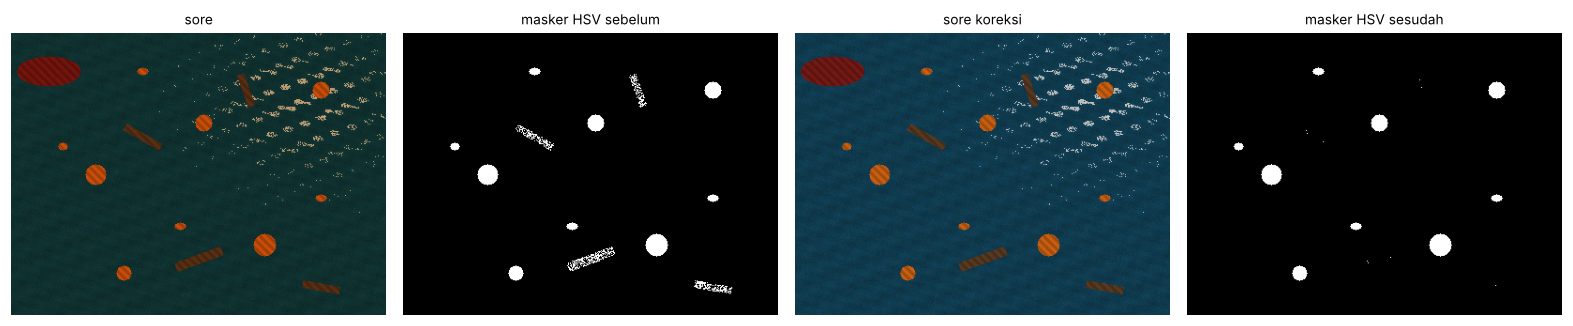

In [18]:
# TODO 5.3 — Koreksi warna cahaya. Kilau adalah pantulan cermin sumber cahaya, jadi warnanya menaksir warna cahaya.
#            Ambil 0,5 % piksel paling terang (jumlah R+G+B) pada laut['sore'], hitung rerata warnanya w = (wR, wG, wB),
#            kalikan tiap kanal dengan max(w)/w_i (transformasi per komponen, Eq. 6-38), lalu jalankan ulang TODO 5.2.
sore = laut['sore']
n = int(np.ceil(0.005 * sore.shape[0] * sore.shape[1]))
idx = np.argsort(sore.astype(float).sum(-1).ravel())[::-1][:n]
w = sore.reshape(-1, 3)[idx].astype(float).mean(0); faktor = w.max() / w
print('Jumlah piksel terang:', n, '| w =', w, '| faktor =', faktor)
sore_koreksi = np.clip(np.floor(sore * faktor + 0.5), 0, 255).astype(np.uint8)
laporkan('Setelah koreksi warna cahaya:', {'sore dikoreksi': sore_koreksi})
tampil([sore, aturan_hsv(sore), sore_koreksi, aturan_hsv(sore_koreksi)], ['sore', 'masker HSV sebelum', 'sore koreksi', 'masker HSV sesudah'], kolom=4, cmap='gray')

**Analisis 5.** (a) Mengapa RGB Euclid dan Lab a*b* yang hampir sempurna di siang runtuh di berawan, sedangkan HSV tidak? (b) Cahaya sore menggagalkan HSV juga. Besaran mana yang bergeser (lihat median TODO 5.1) dan mengapa ambang S = 200 menjadi rapuh? (c) Taksiran warna cahaya dari kilau ternyata sangat tepat. Sebutkan **dua** alasan mengapa hasil ini tidak akan seakurat itu pada foto udara sungguhan. (d) Usulkan urutan pengolahan untuk tim SAR, mulai dari citra mentah sampai masker kandidat rakit.

*Jawaban:*

(a) Saat berawan, citra dikalikan faktor cahaya (0,75, hingga ±0,45 di bayangan awan), sehingga nilai R, G, B dan a*, b* rakit mengecil dan keluar dari bola Euclid yang dilatih dari citra siang. RGB Euclid hanya mendapat IoU 0,030 dan Lab a*b* 0,063 (presisi 1,000, recall sangat rendah). HSV tetap 0,999 karena pengali yang sama pada ketiga kanal tidak mengubah H dan S (median S rakit 233 menjadi 234), dan V masih di atas 40 (median V rakit 217 menjadi 142).

(b) Cahaya sore mengalikan kanal dengan faktor berbeda (1,00; 0,82; 0,60), sehingga yang bergeser adalah perbandingan antarkanal, yaitu saturasi (dan sedikit hue). Median S kayu naik dari 164 (siang) menjadi 200 (sore), sedangkan median S rakit menjadi 242. Ambang S = 200 menjadi rapuh karena pada siang jaraknya hanya 33 dari median rakit (233) dan 36 dari median kayu (164); begitu S kayu naik ke sekitar 200, 800 piksel kayu lolos dan presisi turun menjadi 0,693.

(c) Dua alasan: (1) pada foto sungguhan, kilau bukan pantulan murni warna matahari karena ada pengaruh gamma, white balance kamera, dan pantulan langit atau awan; kilau juga sering jenuh menjadi putih (255, 255, 255) sehingga tidak lagi menyimpan warna cahaya; (2) cahaya pada foto sungguhan tidak seragam (bayangan awan, sudut matahari, gelombang), sedangkan pada citra sintetis ini satu warna cahaya berlaku untuk seluruh citra, sehingga satu taksiran w cukup.

(d) Urutan untuk tim SAR: (1) taksir warna cahaya dari 0,5 % piksel paling terang (di sini w = 199,525; 163,775; 119,887); (2) koreksi tiap kanal dengan faktor maks(w)/w_i (1,000; 1,218; 1,664); (3) ubah ke HSV; (4) terapkan aturan dari citra siang (8 ≤ H ≤ 18, S ≥ 200, V ≥ 40); (5) bersihkan bintik kecil, lalu keluarkan komponen yang tersisa sebagai kandidat rakit. Pada citra sore, langkah ini menaikkan IoU HSV dari 0,693 menjadi 0,995 dan menurunkan piksel kayu yang ikut terdeteksi dari 800 menjadi 9.


## Bagian 6 &mdash; Laporan ilmiah dan pengumpulan (10 menit)

Indikator kedua Sub-CPMK-4 menilai **laporan praktikum sesuai kaidah penulisan ilmiah**. Laporan Bagian 4&ndash;5 disusun maksimal 4 halaman dengan struktur:

1. **Pendahuluan** &mdash; persoalan (deteksi objek berdasarkan warna di bawah cahaya berubah) dan tujuan percobaan.
2. **Metode** &mdash; ruang warna dan aturan yang diuji, **rumus beserta nomor persamaan Gonzalez**, cara memilih ambang, ukuran evaluasi (IoU, presisi, recall).
3. **Hasil** &mdash; satu tabel bernomor dan berjudul (metode &times; kondisi), satu gambar bernomor dengan keterangan. Angka **disalin dari keluaran notebook**, bukan dibulatkan sesuka hati.
4. **Pembahasan** &mdash; justifikasi pilihan ruang warna **dengan angka**; minimal satu paragraf **batas keberlakuan** (kapan metode Anda gagal dan mengapa).
5. **Kesimpulan** &mdash; menjawab tujuan, tanpa klaim baru.
6. **Daftar rujukan** &mdash; gaya Harvard; minimal Gonzalez dan Woods (2018).

Periksa sebelum mengumpulkan:
- [ ] Semua sel berjalan tanpa galat dari atas (Kernel &rarr; Restart & Run All).
- [ ] Setiap blok Analisis memuat angka dari keluaran Anda.
- [ ] Tabel dan gambar di laporan bernomor, berjudul, dan dirujuk di teks.
- [ ] Tidak ada klaim "HSV selalu lebih baik" tanpa syarat.

**Penggunaan alat bantu AI**

1. Claude (Anthropic) membantu menyusun kode sel `TODO` (Bagian 0–5) mengikuti modul praktikum, serta menyusun draf jawaban Analisis 1–5.
2. Pertanggungjawaban: seluruh notebook dijalankan penuh dari atas tanpa galat; hasil konversi diperiksa terhadap hitung tangan (H = 30°, S = 0,6, I = 0,5), uji bolak-balik RGB → HSI → RGB, serta pembanding OpenCV dan `skimage`; setiap angka pada Analisis dicocokkan dengan keluaran sel yang bersangkutan.